# Joint space: range of motion, dimensionality, and a low-dimensional manifold?

The pose label in emg2pose is **20 joint angles** per instant (from the UmeTrack hand model). Questions:

1. **What range of movement is recorded?** Per joint, and per task.
2. **How redundant are the 20 angles?** Correlations between joints, then PCA ("postural synergies").
3. **Is there a lower-dimensional manifold?** Linear dimension (PCA) vs intrinsic dimension (TwoNN), nonlinear embeddings (UMAP, Isomap), and PCA vs a small autoencoder for compression.
4. **So is the 20-D representation "optimal"?**

Data: `~/emg2pose_dataset_mini` (1 user, 15 tasks, both hands), angles downsampled to 50 Hz.

## Setup

**Locally:** run `uv sync --extra cpu` in the repo root and pick the **semg2pose** kernel. The cell below does nothing.

**On Colab:** select *Runtime → Change runtime type → Runtime version 2026.07* (Python 3.12), optionally with a T4 GPU.
Run the cell below once; when it says so, do *Runtime → Restart session* and run the notebook from the top again.

In [1]:
# Colab only: clone semg2pose (with the emg2pose submodule) and install it. Locally this does nothing.
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not (3, 10) <= sys.version_info[:2] < (3, 13):
        raise RuntimeError("Select Runtime > Change runtime type > Runtime version 2026.07 "
                           "(Python 3.12), then run this cell again.")
    REPO_DIR = Path("/content/semg2pose")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--recurse-submodules",
                        "https://github.com/eljoserass/semg2pose.git", str(REPO_DIR)], check=True)
    try:
        import semg2pose  # noqa: F401  (installed in a previous run + restart)
        print("semg2pose is installed, continue.")
    except ImportError:
        subprocess.run(["bash", str(REPO_DIR / "scripts" / "colab_setup.sh")], check=True,
                       env={**os.environ, "PYTHON": sys.executable})
        print("Installed. Now: Runtime > Restart session, then run the notebook from the top.")
else:
    print("Local kernel:", sys.executable)

Local kernel: /home/jose/Documents/projects/neuromatch/semg2pose/.venv/bin/python


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.linalg import subspace_angles
from sklearn.manifold import Isomap
import umap
import torch
from torch import nn

from emg2pose.visualization import skin_mesh_from_angles
from semg2pose.data import FS, FINGER_FLEXION, JOINT_NAMES, download_mini_dataset, load_session

DATASET_DIR = download_mini_dataset()

STEP = 40  # -> 50 Hz
FS_LOW = FS // STEP
plt.rcParams["figure.dpi"] = 100

FLEXION = FINGER_FLEXION  # MCP + PIP flexion of fingers 2-5


/home/jose/Documents/projects/neuromatch/semg2pose/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset already downloaded: /home/jose/emg2pose_dataset_mini


## 1. Load the angles

We keep only valid frames (tracking OK). Each frame keeps its task, hand and session id, plus its time. The time matters for the intrinsic-dimension estimate (section 6): consecutive frames are nearly identical.

In [3]:
frames = []
for sid, path in enumerate(sorted(DATASET_DIR.glob("*.hdf5"))):
    _, angles, ok, meta = load_session(path)
    a, ok = angles[::STEP], ok[::STEP]
    t = np.arange(len(a)) / FS_LOW
    frames.append(pd.DataFrame({"session": sid, "stage": meta["stage"], "side": meta["side"],
                                "t": t[ok]}).join(pd.DataFrame(a[ok], columns=JOINT_NAMES)))
frames = pd.concat(frames, ignore_index=True)
X = frames[JOINT_NAMES].values          # radians
Xdeg = np.degrees(X)
print(f"{len(frames)} valid frames at {FS_LOW} Hz = {len(frames) / FS_LOW / 60:.1f} min "
      f"({frames.session.nunique()} recordings, {frames.stage.nunique()} tasks, 1 user)")
frames.groupby("stage").size().div(FS_LOW).round(0).rename("valid seconds (both hands)").to_frame().T

89012 valid frames at 50 Hz = 29.7 min (30 recordings, 15 tasks, 1 user)


stage,CountingUpDownFaceSideAway,FingerAbductionSeries,FingerFreeform,FingerPinchesSingleFingerPinchesMultiple,FingerWigglingSpreading,HandClawGraspFlicks,HookEmHornsOKScissors,IndividualFingerPointingSnap,OneHandedFreeStyle,ShakaVulcanPeace,ThumbsSwipesWholeHand,ThumbsUpDownThumbRotationsCWCCWP,TwoHandedFreeStyle,WristFlexionAbduction,unconstrained
valid seconds (both hands),112.0,114.0,91.0,106.0,115.0,99.0,111.0,116.0,75.0,103.0,113.0,78.0,380.0,106.0,61.0


## 2. Range of motion

Per joint: 1st percentile, median and 99th percentile, in degrees (percentiles rather than min/max, which are dominated by tracking glitches). Positive FE = flexion (checked by rendering the hand model).

Next to them, a rough **typical active range of motion** for a healthy hand (clinical references; conventions and zero positions differ from the hand model, so compare loosely):

| joint | typical active ROM |
|---|---|
| finger MCP FE | ~−20 (hyperextension) to 90° |
| finger PIP FE | 0 to ~110° |
| finger DIP FE | 0 to ~80° |
| finger MCP AA | ~±20° |
| thumb CMC FE / AA | ~±20–25° / 0–~45° |
| thumb MCP FE | 0 to ~55° |
| thumb IP FE | ~−15 to 80° |

**Not in the 20 angles:** the wrist (flexion/extension, deviation) and forearm pronation/supination. The `WristFlexionAbduction` task moves the wrist, but the labels only see the fingers.

In [4]:
ROM_REF = {"MCP_FE": (-20, 90), "PIP_FE": (0, 110), "DIP_FE": (0, 80), "MCP_AA": (-20, 20),
           "THUMB_CMC_FE": (-20, 25), "THUMB_CMC_AA": (0, 45), "THUMB_MCP_FE": (0, 55), "THUMB_IP_FE": (-15, 80)}


def ref_for(name):
    if name in ROM_REF:
        return ROM_REF[name]
    return ROM_REF["_".join(name.split("_")[1:])]


q = np.percentile(Xdeg, [1, 50, 99], axis=0)
rom = pd.DataFrame({"p1": q[0], "median": q[1], "p99": q[2], "range p1-p99": q[2] - q[0],
                    "ref low": [ref_for(n)[0] for n in JOINT_NAMES],
                    "ref high": [ref_for(n)[1] for n in JOINT_NAMES]}, index=JOINT_NAMES).round(0)
rom["% of ref range used"] = (100 * rom["range p1-p99"] / (rom["ref high"] - rom["ref low"])).round(0)
rom

,p1,median,p99,range p1-p99,ref low,ref high,% of ref range used
THUMB_CMC_FE,-20.0,8.0,42.0,62.0,-20,25,138.0
THUMB_CMC_AA,-28.0,-6.0,22.0,50.0,0,45,111.0
THUMB_MCP_FE,-5.0,14.0,52.0,57.0,0,55,104.0
THUMB_IP_FE,-20.0,38.0,67.0,87.0,-15,80,92.0
INDEX_MCP_AA,-22.0,-4.0,16.0,38.0,-20,20,95.0
INDEX_MCP_FE,-21.0,17.0,72.0,93.0,-20,90,85.0
INDEX_PIP_FE,-5.0,26.0,113.0,118.0,0,110,107.0
INDEX_DIP_FE,-5.0,11.0,79.0,84.0,0,80,105.0
MIDDLE_MCP_AA,-24.0,-6.0,19.0,43.0,-20,20,108.0
MIDDLE_MCP_FE,-21.0,21.0,80.0,101.0,-20,90,92.0


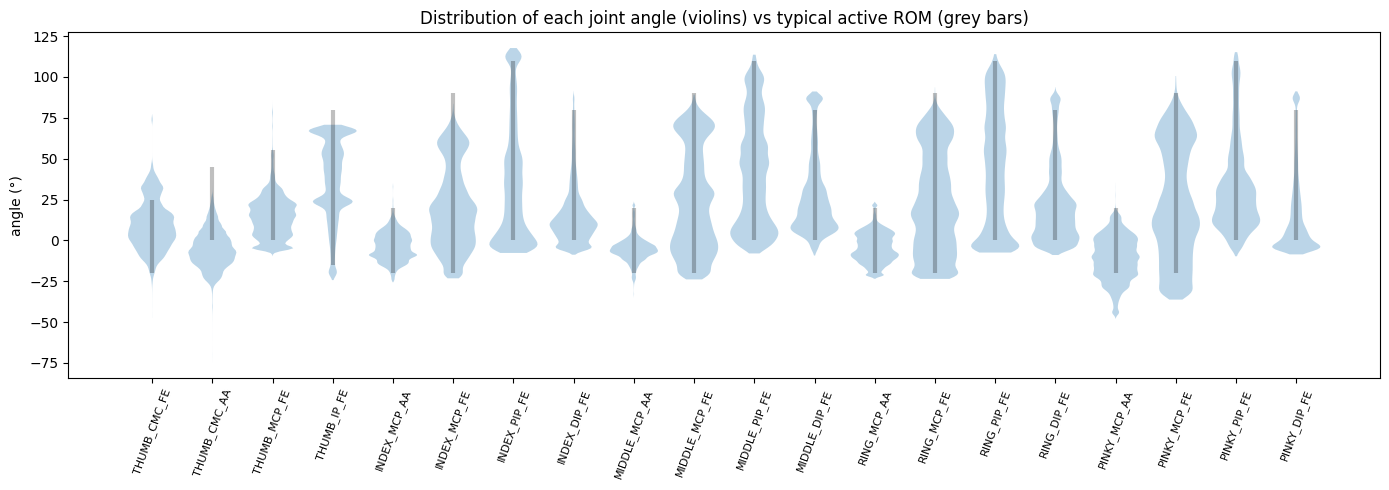

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.violinplot([Xdeg[:, j] for j in range(20)], showextrema=False, widths=0.8)
for j, n in enumerate(JOINT_NAMES):
    lo, hi = ref_for(n)
    ax.plot([j + 1, j + 1], [lo, hi], color="k", lw=3, alpha=0.25, solid_capstyle="butt")
ax.set_xticks(range(1, 21), JOINT_NAMES, rotation=70, fontsize=8)
ax.set_ylabel("angle (°)")
ax.set_title("Distribution of each joint angle (violins) vs typical active ROM (grey bars)")
plt.tight_layout()
plt.show()

**Which task moves which joint?** Standard deviation of each joint within each task (both hands pooled). Light = that task explores that joint a lot.

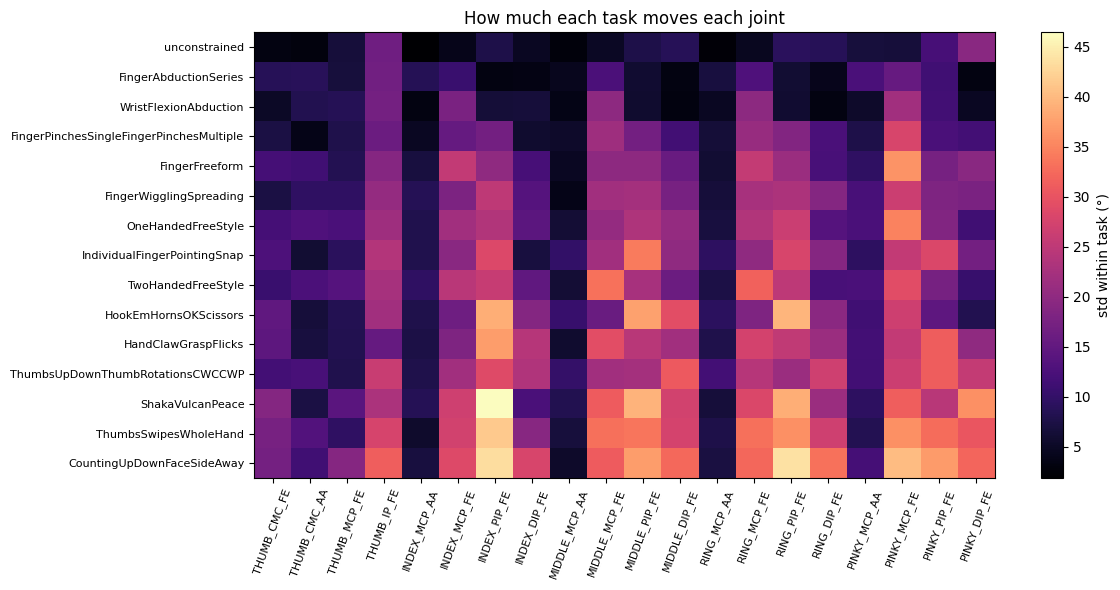

In [6]:
task_std = frames.groupby("stage")[JOINT_NAMES].std().apply(np.degrees)
task_std = task_std.loc[task_std.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(task_std.values, cmap="magma", aspect="auto")
ax.set_xticks(range(20), JOINT_NAMES, rotation=70, fontsize=8)
ax.set_yticks(range(len(task_std)), task_std.index, fontsize=8)
plt.colorbar(im, ax=ax, label="std within task (°)")
ax.set_title("How much each task moves each joint")
plt.tight_layout()
plt.show()

**Range of motion, in short:** the recorded range is essentially the **full active range** of every finger joint. The median joint covers ~106 % of the typical clinical range: PIP up to ~110°, DIP up to ~85°, MCP from ~−20° (hyperextension) to ~80°. Thumb CMC and pinky AA exceed the reference, partly because the hand model's zero position and conventions differ from clinical goniometry. No joint is under-sampled at the extremes. But single tasks are narrow: e.g. `FingerAbductionSeries` and `unconstrained` barely move anything (std ~40° summed over joints vs ~130° for `CountingUpDownFaceSideAway`).

## 3. Joint–joint correlations

Strong coupling means redundancy. Expected: **PIP–DIP** of the same finger (mechanically linked by the tendons), the **same joint on neighbouring fingers** (shared muscles such as flexor digitorum and extensor digitorum, which drive fingers 2–5 together), and **AA vs FE** being more independent.

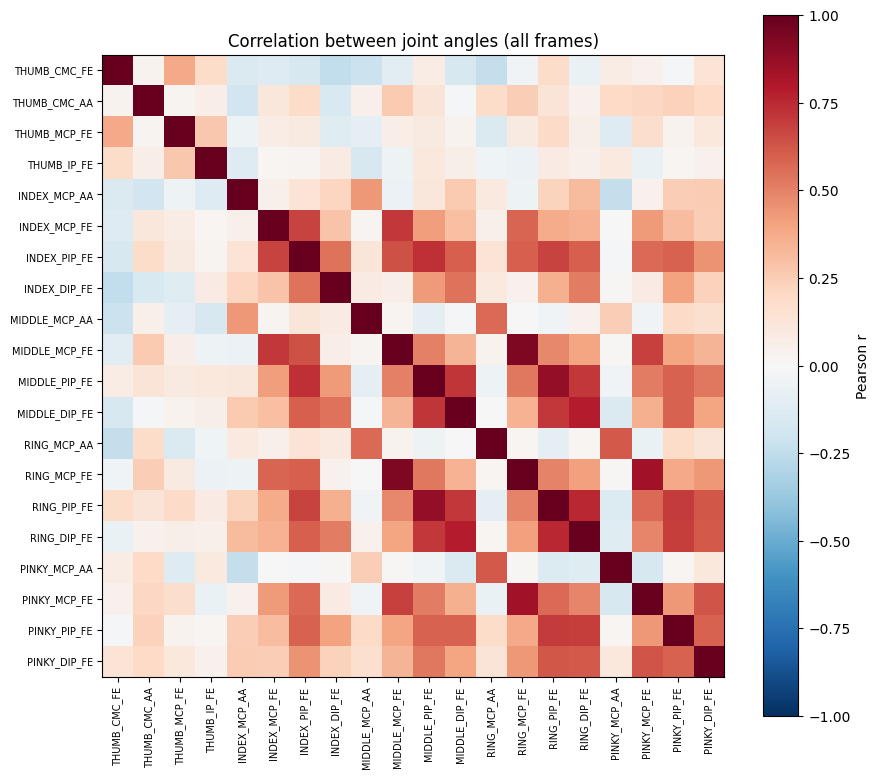

,r
INDEX_PIP_FE – INDEX_DIP_FE,0.55
MIDDLE_PIP_FE – MIDDLE_DIP_FE,0.72
RING_PIP_FE – RING_DIP_FE,0.75
PINKY_PIP_FE – PINKY_DIP_FE,0.59
INDEX_MCP_FE – MIDDLE_MCP_FE,0.71
MIDDLE_MCP_FE – RING_MCP_FE,0.93
RING_MCP_FE – PINKY_MCP_FE,0.84
INDEX_MCP_FE – PINKY_MCP_FE,0.42
THUMB_IP_FE – INDEX_PIP_FE,0.03
INDEX_MCP_AA – INDEX_MCP_FE,0.05


In [7]:
Cj = np.corrcoef(X.T)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(Cj, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(20), JOINT_NAMES, rotation=90, fontsize=7)
ax.set_yticks(range(20), JOINT_NAMES, fontsize=7)
plt.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Correlation between joint angles (all frames)")
plt.tight_layout()
plt.show()

pairs = [(f"{f}_PIP_FE", f"{f}_DIP_FE") for f in ["INDEX", "MIDDLE", "RING", "PINKY"]] + \
        [("INDEX_MCP_FE", "MIDDLE_MCP_FE"), ("MIDDLE_MCP_FE", "RING_MCP_FE"), ("RING_MCP_FE", "PINKY_MCP_FE"),
         ("INDEX_MCP_FE", "PINKY_MCP_FE"), ("THUMB_IP_FE", "INDEX_PIP_FE"), ("INDEX_MCP_AA", "INDEX_MCP_FE")]
pd.Series({f"{a} – {b}": Cj[JOINT_NAMES.index(a), JOINT_NAMES.index(b)] for a, b in pairs},
          name="r").round(2).to_frame()

Coupling as expected: **MCP flexion of middle–ring (r 0.93) and ring–pinky (0.84)** are nearly the same signal, index is more independent (index–pinky 0.42), PIP–DIP 0.55–0.75. Thumb and AA joints are almost uncorrelated with finger flexion (r ≈ 0): they are separate degrees of freedom.

## 4. PCA: how many linear dimensions?

PCA on the angles (radians, all joints in the same units, so no standardisation: a joint that moves more counts more).

- **Cumulative explained variance**: how many components for 90 % / 95 %.
- **Participation ratio** PR = (Σλ)² / Σλ²: an "effective number of dimensions" (1 if all variance is in one PC, 20 if spread evenly).

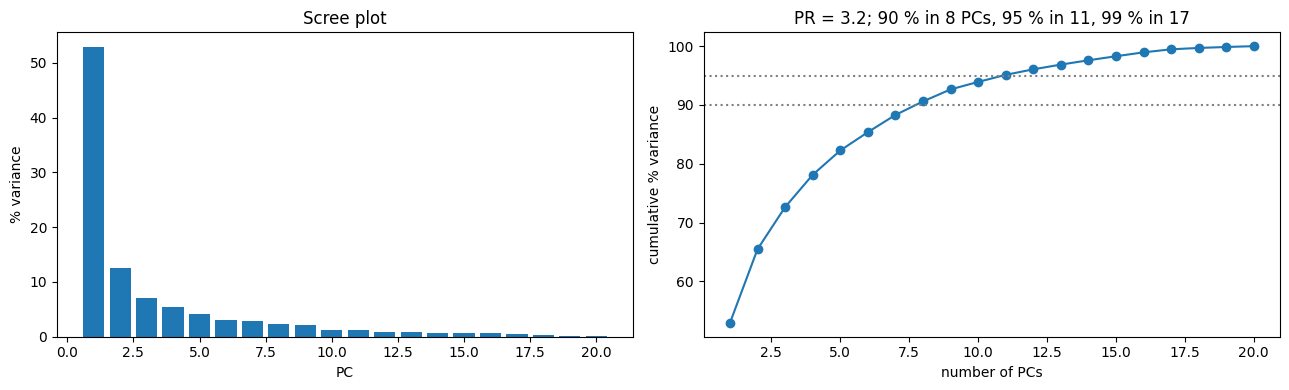

PC1 53 %, PC1-3 73 %, participation ratio 3.2


In [8]:
mean_pose = X.mean(axis=0)
Xc = X - mean_pose
U, svals, Vt = np.linalg.svd(Xc, full_matrices=False)
eigvals = svals ** 2 / (len(X) - 1)
explained = eigvals / eigvals.sum()
cum = np.cumsum(explained)
PR = eigvals.sum() ** 2 / (eigvals ** 2).sum()
n90, n95, n99 = [int(np.searchsorted(cum, p) + 1) for p in (0.90, 0.95, 0.99)]
scores = Xc @ Vt.T

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.bar(range(1, 21), 100 * explained)
ax1.set_xlabel("PC")
ax1.set_ylabel("% variance")
ax1.set_title("Scree plot")
ax2.plot(range(1, 21), 100 * cum, "o-")
for p in (90, 95):
    ax2.axhline(p, color="gray", ls=":")
ax2.set_xlabel("number of PCs")
ax2.set_ylabel("cumulative % variance")
ax2.set_title(f"PR = {PR:.1f}; 90 % in {n90} PCs, 95 % in {n95}, 99 % in {n99}")
plt.tight_layout()
plt.show()
print(f"PC1 {100 * explained[0]:.0f} %, PC1-3 {100 * cum[2]:.0f} %, participation ratio {PR:.1f}")

### Eigen-postures: what does each PC look like?

We render the UmeTrack hand mesh at the mean pose and at mean ± 2 standard deviations along PC1–PC4. The 20 joint loadings are also shown as bars.

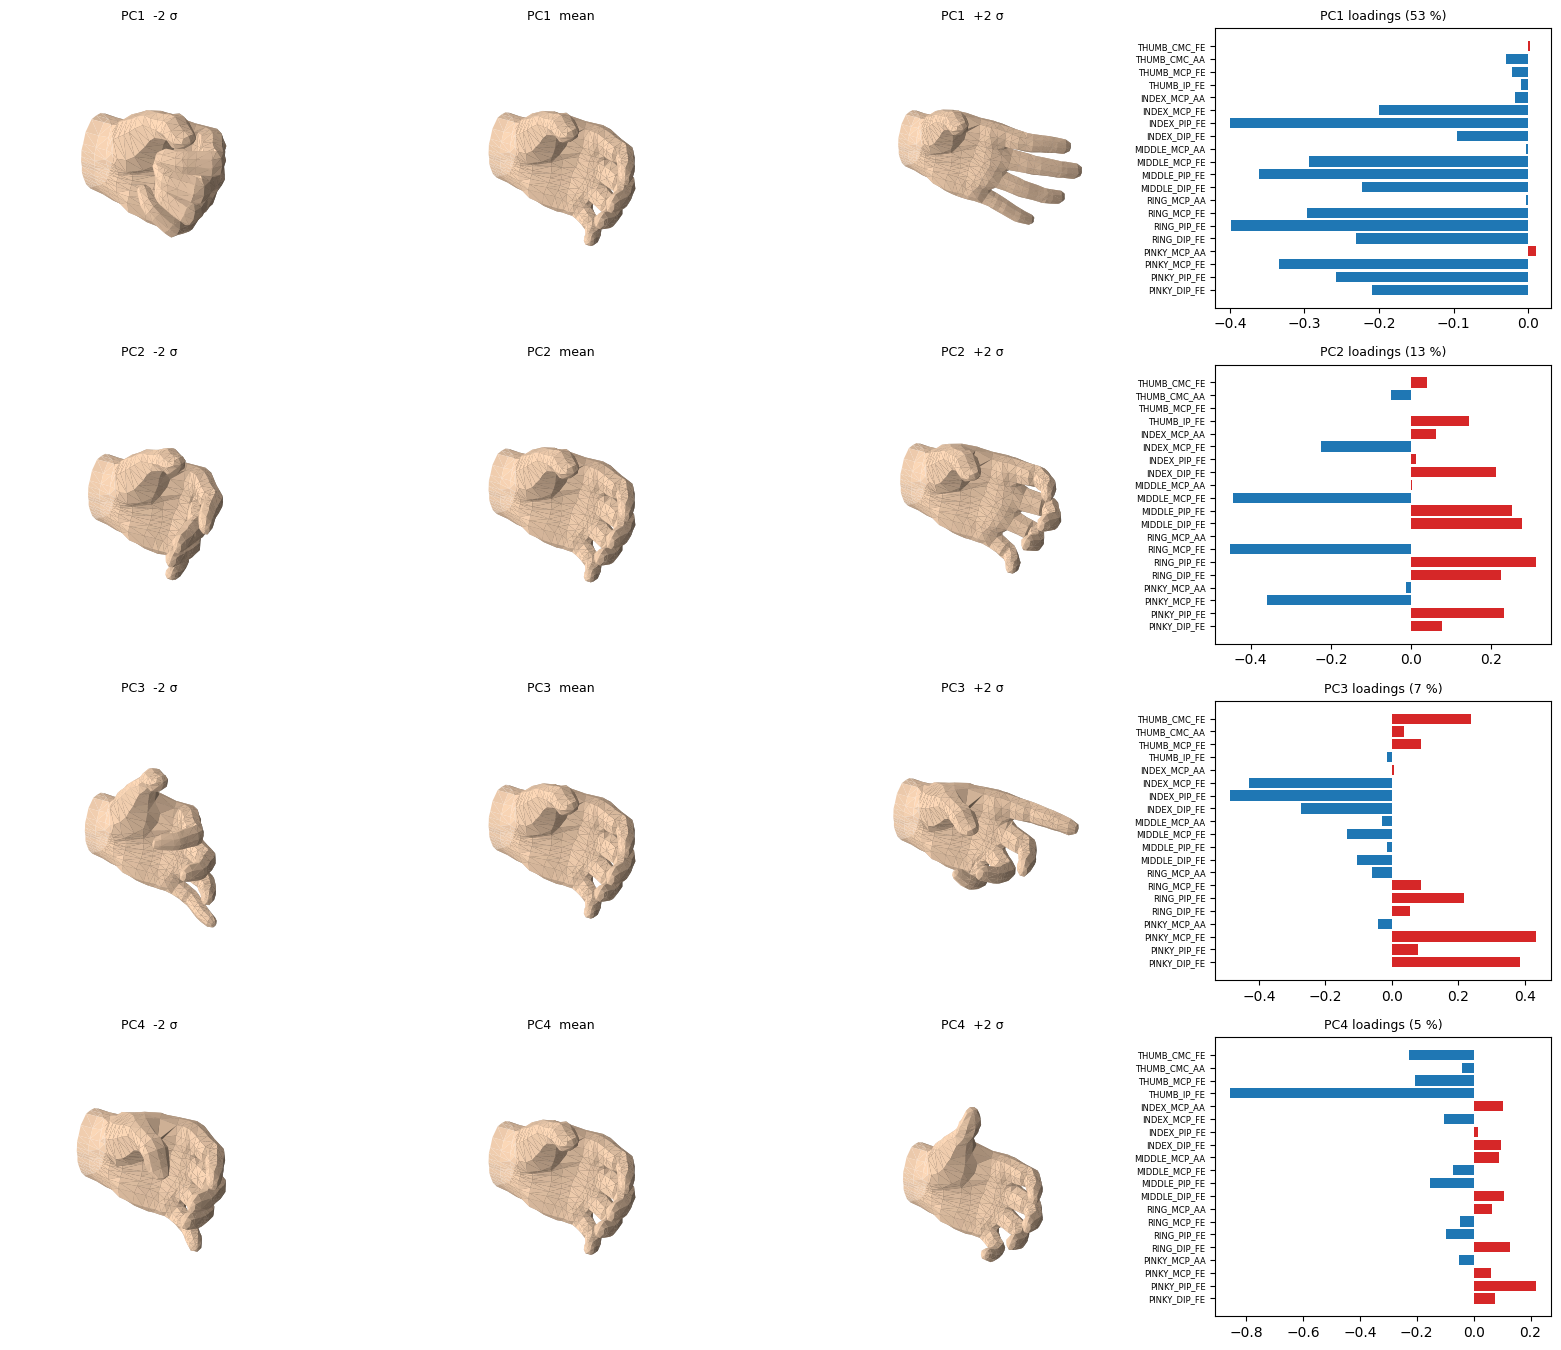

In [9]:
def draw_hand(ax, angles, title=""):
    v, tri = skin_mesh_from_angles(angles)
    ax.plot_trisurf(v[:, 0], v[:, 1], v[:, 2], triangles=np.asarray(tri), color="peachpuff",
                    edgecolor="none", shade=True)
    ax.view_init(20, -60)
    ax.set_box_aspect(np.ptp(v, axis=0))
    ax.set_axis_off()
    ax.set_title(title, fontsize=9)


N_SHOW = 4
fig = plt.figure(figsize=(16, 3.4 * N_SHOW))
for k in range(N_SHOW):
    sd = np.sqrt(eigvals[k])
    for i, m in enumerate([-2, 0, 2]):
        ax = fig.add_subplot(N_SHOW, 4, 4 * k + i + 1, projection="3d")
        draw_hand(ax, mean_pose + m * sd * Vt[k], f"PC{k + 1}  {m:+d} σ" if m else f"PC{k + 1}  mean")
    ax = fig.add_subplot(N_SHOW, 4, 4 * k + 4)
    ax.barh(range(20), Vt[k], color=np.where(Vt[k] > 0, "tab:red", "tab:blue"))
    ax.set_yticks(range(20), JOINT_NAMES, fontsize=6)
    ax.invert_yaxis()
    ax.set_title(f"PC{k + 1} loadings ({100 * explained[k]:.0f} %)", fontsize=9)
plt.tight_layout()
plt.show()

- **PC1 (53 %)**: open ↔ close the four fingers together (mainly PIP and MCP; the thumb barely participates). This is the classic first "postural synergy".
- **PC2 (13 %)**: MCP vs PIP/DIP: a flat "table-top / duck-bill" hand vs a hook/claw.
- **PC3 (7 %)**: index vs pinky (pointing vs pinky curl): finger individuation.
- **PC4 (5 %)**: thumb IP/CMC: thumbs-up vs thumb tucked.

After PC4, each component is mostly one finger or one AA joint moving on its own.

## 5. Is the low-dimensional structure shared across tasks?

For each task: how many PCs it needs for 90 %, and the subspace spanned by its top 5 PCs. The **overlap** between two tasks is the mean squared cosine of the principal angles between their 5-D subspaces: 1 means the same subspace, ~5/20 = 0.25 is what two random 5-D subspaces of 20-D space would give.

If all tasks share one low-dimensional "synergy" space, the overlap should be high everywhere.

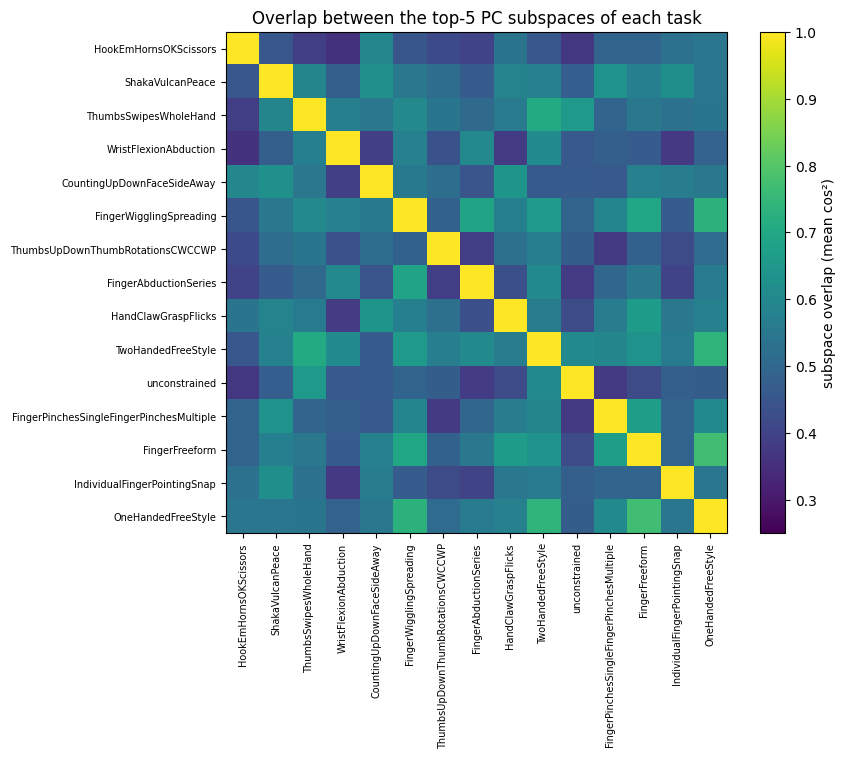

Off-diagonal overlap: median 0.54, min 0.36, max 0.77 (random ≈ 0.25)


,PCs for 90 %,PC1 %,total std (°)
stage,,,
HookEmHornsOKScissors,4,57,96
ShakaVulcanPeace,4,52,115
ThumbsSwipesWholeHand,4,69,117
WristFlexionAbduction,4,70,50
CountingUpDownFaceSideAway,5,60,130
FingerWigglingSpreading,5,65,78
ThumbsUpDownThumbRotationsCWCCWP,5,65,97
FingerAbductionSeries,6,36,42
HandClawGraspFlicks,6,66,95


In [10]:
K_SUB = 5
stages = sorted(frames.stage.unique())
bases, per_task = {}, []
for st in stages:
    Z = X[frames.stage.values == st]
    Zc = Z - Z.mean(0)
    _, s, vt = np.linalg.svd(Zc, full_matrices=False)
    c = np.cumsum(s ** 2) / (s ** 2).sum()
    bases[st] = vt[:K_SUB].T
    per_task.append({"stage": st, "PCs for 90 %": int(np.searchsorted(c, 0.9) + 1),
                     "PC1 %": round(100 * c[0]), "total std (°)": round(np.degrees(np.sqrt((Zc ** 2).sum(1).mean())))})
per_task = pd.DataFrame(per_task).set_index("stage").sort_values("PCs for 90 %")

overlap = np.array([[np.mean(np.cos(subspace_angles(bases[a], bases[b])) ** 2) for b in stages] for a in stages])
order = list(per_task.index)
idx = [stages.index(s) for s in order]
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(overlap[np.ix_(idx, idx)], cmap="viridis", vmin=0.25, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=7)
ax.set_yticks(range(len(order)), order, fontsize=7)
plt.colorbar(im, ax=ax, label="subspace overlap (mean cos²)")
ax.set_title(f"Overlap between the top-{K_SUB} PC subspaces of each task")
plt.tight_layout()
plt.show()
off = overlap[~np.eye(len(stages), dtype=bool)]
print(f"Off-diagonal overlap: median {np.median(off):.2f}, min {off.min():.2f}, max {off.max():.2f} (random ≈ {K_SUB / 20:.2f})")
per_task

## 6. Intrinsic dimension (TwoNN)

PCA gives the number of **linear** directions needed. If the data lie on a **curved** surface (e.g. a 3-D sheet bent through 20-D space), PCA overestimates the dimension. **TwoNN** (Facco et al. 2017) estimates the intrinsic dimension from the ratio μ = r₂/r₁ of the distances to the 2nd and 1st nearest neighbours: for data of dimension d, μ follows a Pareto law with exponent d, so d̂ = N / Σ log μ.

**A pitfall with time series:** at 50 Hz the nearest neighbour of a frame is usually the next frame of the same movement. TwoNN would then measure the dimension of the *trajectory* (≈ 1). We exclude neighbours from the same recording within ±1 s, and also compute the naive version to show the bias.

TwoNN is scale-dependent. We repeat it on random subsamples of different sizes (fewer points = larger neighbour distances = coarser scale).

In [11]:
def twonn(Z, session, t, exclude_s=1.0, k=60, rng=None):
    tree = cKDTree(Z)
    d, nn = tree.query(Z, k=k + 1)
    d, nn = d[:, 1:], nn[:, 1:]
    if exclude_s is not None:
        bad = (session[nn] == session[:, None]) & (np.abs(t[nn] - t[:, None]) < exclude_s)
        d = np.where(bad, np.inf, d)
        d = np.sort(d, axis=1)
    r1, r2 = d[:, 0], d[:, 1]
    keep = np.isfinite(r2) & (r1 > 0)
    mu = r2[keep] / r1[keep]
    mu = np.sort(mu)[: int(0.9 * len(mu))]  # drop the top 10 % (outliers), as in the paper
    return len(mu) / np.sum(np.log(mu))


rng = np.random.default_rng(0)
sess, tt = frames.session.values, frames.t.values
rows = []
for n in [2000, 5000, 20000, len(X)]:
    sub = rng.choice(len(X), size=min(n, len(X)), replace=False)
    rows.append({"N points": len(sub),
                 "TwoNN, neighbours within 1 s excluded": twonn(X[sub], sess[sub], tt[sub]),
                 "TwoNN, naive": twonn(X[sub], sess[sub], tt[sub], exclude_s=None)})
twonn_table = pd.DataFrame(rows).set_index("N points").round(1)
print(f"PCA: participation ratio {PR:.1f}, {n90} PCs for 90 %, {n95} for 95 %")
twonn_table

PCA: participation ratio 3.2, 8 PCs for 90 %, 11 for 95 %


,"TwoNN, neighbours within 1 s excluded","TwoNN, naive"
N points,,
2000,8.5,5.8
5000,9.0,4.8
20000,12.6,3.9
89012,20.5,5.4


**Reading the TwoNN numbers.** The estimate depends on the scale:

- With **few points** (coarse scale, neighbours far apart) it gives **~8–9**, close to the 8 PCs needed for 90 % variance. At the scale of real postural differences, the data fill about as many dimensions as PCA says: there is **no hidden, much lower-dimensional curved manifold**.
- With **all points** (fine scale) it climbs to **~20**. At sub-degree distances, tracking jitter and small independent movements fill every direction, so locally the data are full-dimensional noise.
- The **naive version (~4–6)** is biased low by trajectory neighbours (the next frame of the same movement). It is the number you would get by mistake.

## 7. Nonlinear embeddings: UMAP and Isomap

2-D maps of joint space, coloured by **task** and by **mean finger flexion**. These are pictures, not measurements: UMAP preserves local neighbourhoods and distorts global distances. Isomap tries to preserve geodesic distances along the manifold (on a smaller subsample, since it is O(N²)).

We subsample to 10 Hz for UMAP.

/home/jose/Documents/projects/neuromatch/semg2pose/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


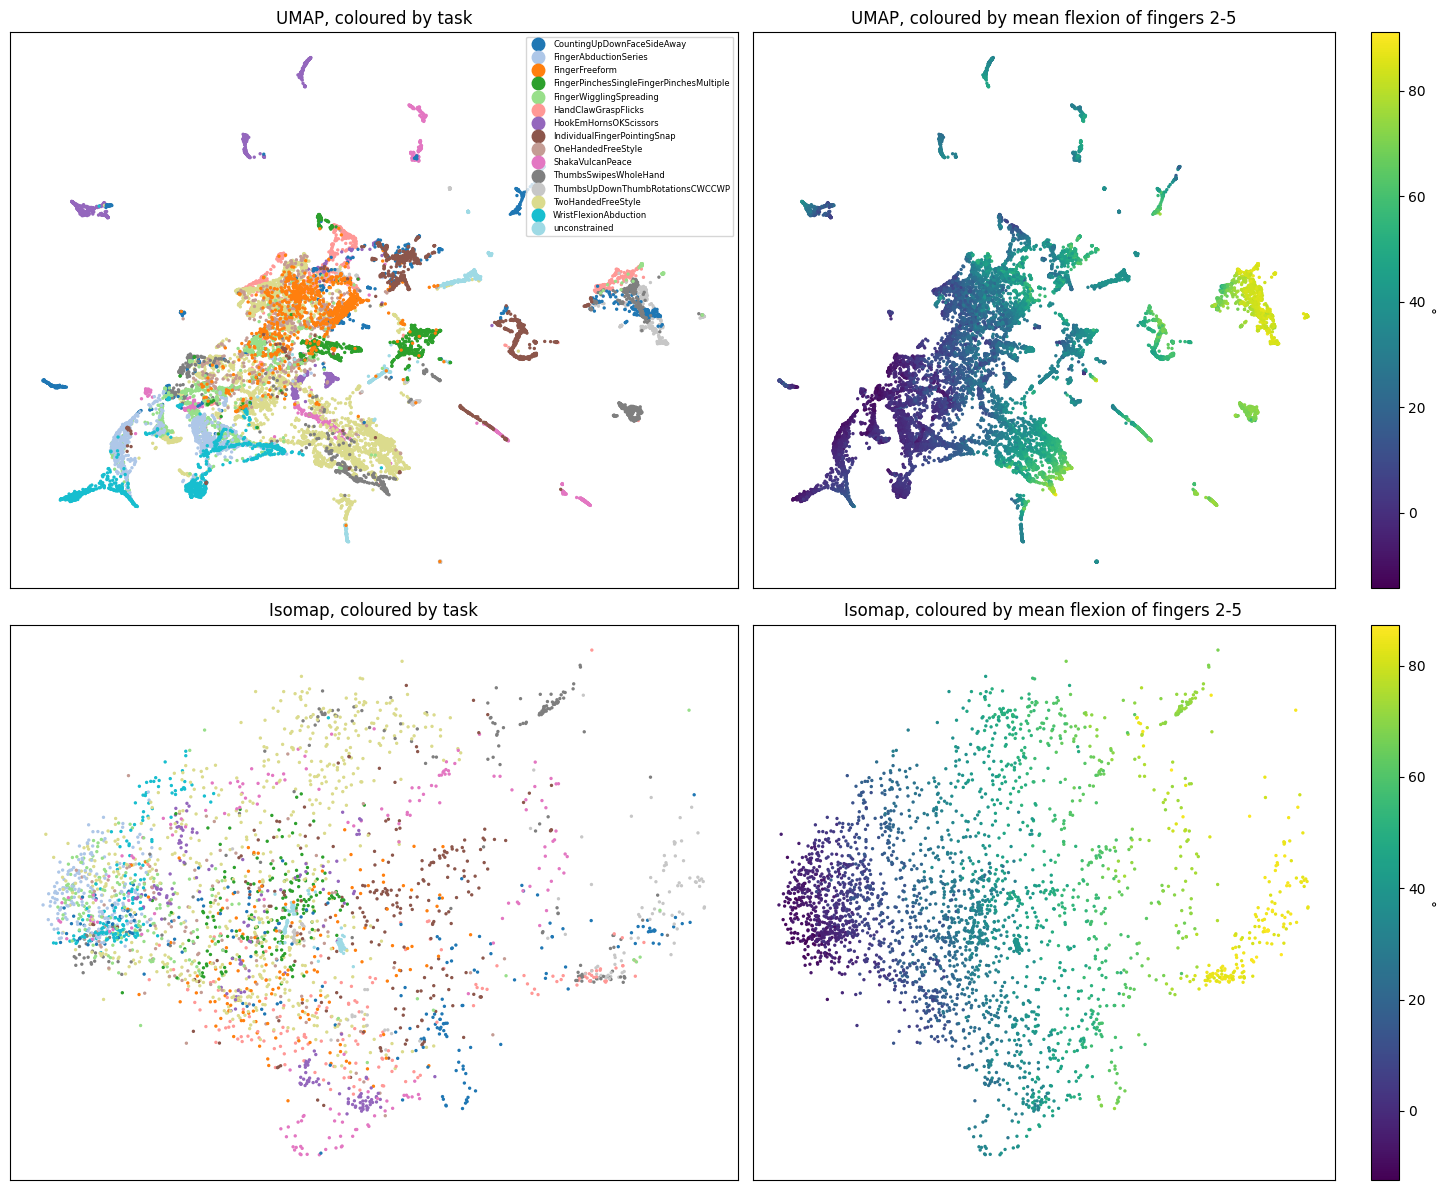

In [12]:
sub_u = np.arange(0, len(X), 5)  # 10 Hz
emb_u = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=0).fit_transform(X[sub_u])
sub_i = rng.choice(len(X), size=3000, replace=False)
emb_i = Isomap(n_neighbors=15, n_components=2).fit_transform(X[sub_i])

flex = np.degrees(X[:, FLEXION].mean(axis=1))
codes = pd.Categorical(frames.stage).codes
cmap_task = plt.get_cmap("tab20", len(stages))
fig, axs = plt.subplots(2, 2, figsize=(15, 12))
for row, (emb, sub, name) in enumerate([(emb_u, sub_u, "UMAP"), (emb_i, sub_i, "Isomap")]):
    sc = axs[row, 0].scatter(emb[:, 0], emb[:, 1], c=codes[sub], cmap=cmap_task, s=2,
                             vmin=-0.5, vmax=len(stages) - 0.5)
    axs[row, 0].set_title(f"{name}, coloured by task")
    sc2 = axs[row, 1].scatter(emb[:, 0], emb[:, 1], c=flex[sub], cmap="viridis", s=2)
    axs[row, 1].set_title(f"{name}, coloured by mean flexion of fingers 2-5")
    plt.colorbar(sc2, ax=axs[row, 1], label="°")
handles = [plt.Line2D([], [], ls="", marker="o", color=cmap_task(i), label=s) for i, s in enumerate(stages)]
axs[0, 0].legend(handles=handles, fontsize=6, markerscale=1.5, loc="best")
for ax in axs.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

UMAP breaks the data into islands, most of them single tasks (held postures such as Shaka/Vulcan/OK-sign, thumb rotations). A large central blob holds the free-form and finger tasks, ordered by flexion. Isomap shows one continuous sheet whose main axis is flexion (≈ PC1). The structure is "a continuum of open↔closed, plus discrete postures that only some tasks visit", not a single thin curve.

### One task as a trajectory in PC space

`HandClawGraspFlicks` (right hand), 30 s in the PC1–PC2 plane, coloured by time, on top of all the data in grey. Movements are **loops** between a few postures, and much of the plane is visited by other tasks.

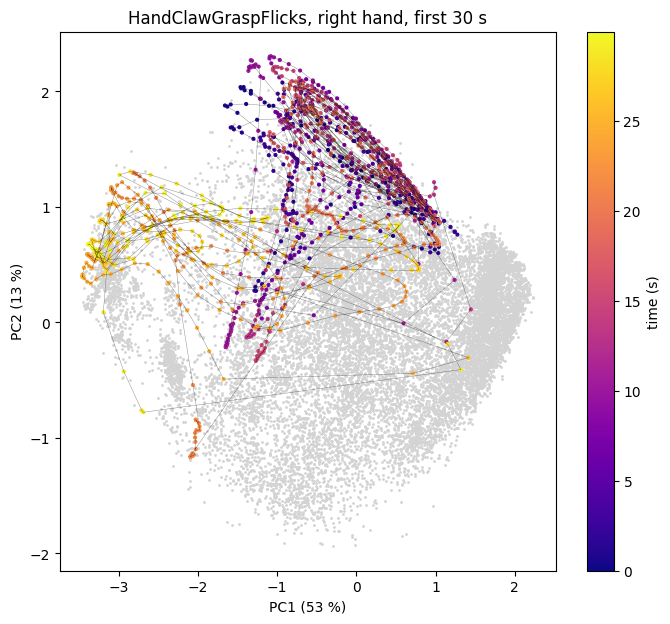

In [13]:
m = (frames.stage.values == "HandClawGraspFlicks") & (frames.side.values == "right") & (frames.t.values < 30)
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(scores[::5, 0], scores[::5, 1], s=1, color="lightgray")
ax.plot(scores[m, 0], scores[m, 1], color="k", lw=0.3, alpha=0.5)
sc = ax.scatter(scores[m, 0], scores[m, 1], c=frames.t.values[m], cmap="plasma", s=4)
plt.colorbar(sc, ax=ax, label="time (s)")
ax.set_xlabel(f"PC1 ({100 * explained[0]:.0f} %)")
ax.set_ylabel(f"PC2 ({100 * explained[1]:.0f} %)")
ax.set_title("HandClawGraspFlicks, right hand, first 30 s")
plt.show()

## 8. Compression: PCA vs a nonlinear autoencoder

If the manifold is curved, a nonlinear encoder–decoder should reconstruct the 20 angles better than PCA with the same latent size *k*.

- Split by **task**: 3 tasks (both hands) held out as the test set, so test postures were not seen in training.
- PCA fitted on train. Autoencoder: 20 → 128 → 64 → k → 64 → 128 → 20 (ELU), Adam, 25 epochs, CPU.
- Metric: test RMSE in degrees, averaged over joints.

train 74424 frames, test 14588 frames (FingerPinchesSingleFingerPinchesMultiple, HookEmHornsOKScissors, OneHandedFreeStyle)


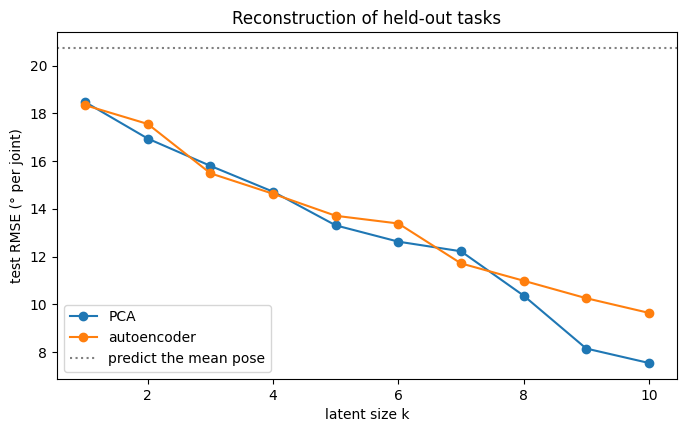

Mean-pose baseline: 20.7°


latent size k,1,2,3,4,5,6,7,8,9,10
PCA,18.47,16.94,15.80,14.72,13.31,12.63,12.22,10.37,8.15,7.54
autoencoder,18.34,17.56,15.49,14.63,13.71,13.39,11.72,10.99,10.26,9.64


In [14]:
TEST_TASKS = ["FingerPinchesSingleFingerPinchesMultiple", "HookEmHornsOKScissors", "OneHandedFreeStyle"]
is_test = frames.stage.isin(TEST_TASKS).values
Xtr, Xte = X[~is_test], X[is_test]
mu_tr, sd_tr = Xtr.mean(0), Xtr.std(0)
print(f"train {len(Xtr)} frames, test {len(Xte)} frames ({', '.join(TEST_TASKS)})")

_, _, Vt_tr = np.linalg.svd(Xtr - mu_tr, full_matrices=False)


def rmse_deg(A, B):
    return float(np.degrees(np.sqrt(((A - B) ** 2).mean())))


def pca_rmse(k):
    W = Vt_tr[:k]
    return rmse_deg(Xte, (Xte - mu_tr) @ W.T @ W + mu_tr)


def ae_rmse(k, epochs=25, seed=0):
    torch.manual_seed(seed)
    enc = nn.Sequential(nn.Linear(20, 128), nn.ELU(), nn.Linear(128, 64), nn.ELU(), nn.Linear(64, k))
    dec = nn.Sequential(nn.Linear(k, 64), nn.ELU(), nn.Linear(64, 128), nn.ELU(), nn.Linear(128, 20))
    model = nn.Sequential(enc, dec)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    xt = torch.tensor((Xtr - mu_tr) / sd_tr, dtype=torch.float32)
    for _ in range(epochs):
        perm = torch.randperm(len(xt))
        for i in range(0, len(xt), 512):
            b = xt[perm[i:i + 512]]
            loss = ((model(b) - b) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
    with torch.no_grad():
        rec = model(torch.tensor((Xte - mu_tr) / sd_tr, dtype=torch.float32)).numpy() * sd_tr + mu_tr
    return rmse_deg(Xte, rec)


torch.set_num_threads(4)
KS = list(range(1, 11))
comp = pd.DataFrame({"PCA": [pca_rmse(k) for k in KS], "autoencoder": [ae_rmse(k) for k in KS]}, index=KS)
comp.index.name = "latent size k"
baseline = rmse_deg(Xte, np.broadcast_to(mu_tr, Xte.shape))

ax = comp.plot(marker="o", figsize=(8, 4.5))
ax.axhline(baseline, color="gray", ls=":", label="predict the mean pose")
ax.set_ylabel("test RMSE (° per joint)")
ax.set_title("Reconstruction of held-out tasks")
ax.legend()
plt.show()
print(f"Mean-pose baseline: {baseline:.1f}°")
comp.round(2).T

**PCA vs autoencoder:** on held-out tasks the autoencoder is **no better than PCA** at any k (k=4: 14.6° vs 14.7°; at k ≥ 8 it is worse, partly undertrained and partly overfitting the training tasks). Even with 8 dimensions the test error is ~10° per joint, against 20.7° for just predicting the mean pose. The unseen tasks contain postures whose fine detail lives in directions the training tasks rarely use.

## 9. Conclusions

Numbers recomputed from this run:

In [15]:
used = rom["% of ref range used"]
print(f"Data: {len(frames) / FS_LOW / 60:.1f} valid min, 1 user, 15 tasks, both hands")
print(f"ROM: median joint covers {used.median():.0f} % of the typical active range "
      f"(min {used.min():.0f} % {used.idxmin()}, max {used.max():.0f} % {used.idxmax()})")
print(f"PCA: PC1 {100 * explained[0]:.0f} %, participation ratio {PR:.1f}, 90 % in {n90} PCs, 95 % in {n95}, 99 % in {n99}")
print(f"Per task: {per_task['PCs for 90 %'].min()}-{per_task['PCs for 90 %'].max()} PCs for 90 %; "
      f"subspace overlap between tasks median {np.median(off):.2f} (random {K_SUB / 20:.2f})")
print("TwoNN intrinsic dimension (1 s exclusion):", twonn_table.iloc[:, 0].to_dict())
print("TwoNN naive (trajectory bias):          ", twonn_table.iloc[:, 1].to_dict())
for k in (2, 4, 8):
    print(f"k={k}: test RMSE PCA {comp.loc[k, 'PCA']:.2f}°, autoencoder {comp.loc[k, 'autoencoder']:.2f}°")

Data: 29.7 valid min, 1 user, 15 tasks, both hands
ROM: median joint covers 106 % of the typical active range (min 85 % INDEX_MCP_FE, max 150 % PINKY_MCP_AA)
PCA: PC1 53 %, participation ratio 3.2, 90 % in 8 PCs, 95 % in 11, 99 % in 17
Per task: 4-8 PCs for 90 %; subspace overlap between tasks median 0.54 (random 0.25)
TwoNN intrinsic dimension (1 s exclusion): {2000: 8.5, 5000: 9.0, 20000: 12.6, 89012: 20.5}
TwoNN naive (trajectory bias):           {2000: 5.8, 5000: 4.8, 20000: 3.9, 89012: 5.4}
k=2: test RMSE PCA 16.94°, autoencoder 17.56°
k=4: test RMSE PCA 14.72°, autoencoder 14.63°
k=8: test RMSE PCA 10.37°, autoencoder 10.99°


**What range of movement is recorded?** Close to the full active range of every finger joint (PIP 0–110°, DIP 0–85°, MCP −20–80°, AA ±20°, thumb included), over 15 tasks from near-rest to fist, pinches, counting and free play. No wrist or forearm angles. The mini dataset is 1 user and ~30 valid minutes, so treat every number here as "this person", not "people".

**Is there a lower-dimensional structure?** Yes, but it is not dramatically low:

- A few **linear synergies** dominate: PC1 (open/close) has 53 %, PC1–3 have 73 %, and the effective dimension (participation ratio) is ~3.2. Any single task lives in a 4–8-D subspace, and tasks share a good part of it (overlap 0.54 vs 0.25 for random subspaces).
- But **8 PCs for 90 % and 11 for 95 %**, and TwoNN agrees (~8–9 at the coarse scale). There is **no evidence of a curved manifold** that a nonlinear method would compress better: the autoencoder does no better than PCA.

**Is the 20-D representation already optimal?** It is not a compressed code. It is a *kinematic parameterisation* (one number per anatomical degree of freedom) with lots of redundancy at the coarse level (fingers 3–5 move together, PIP–DIP are coupled). So:

- **To visualise**, PC1–PC2 (or UMAP) plus the eigen-posture renders are fine. Plot trajectories in that plane.
- **To compress the target** (e.g. predict a few synergy scores from EMG instead of 20 angles), 3–4 PCs keep the gross hand shape (~70–80 % of variance), but the **tail is the interesting part**: PCs 3+ are individual fingers, thumb and abduction, exactly the movements that distinguish an OK sign from a pinch. Dropping them costs ~10–15° per joint on unseen tasks.
- A useful **middle ground**: predict angles in PCA coordinates (an orthogonal rotation, nothing is lost) and weight or regularise the tail differently. Or report errors separately for the "synergy" part (PC1–3) and the "individuation" part (the rest). That ties directly to the EMG question: which of these components can the EMG actually see? See `emg_angle_correlation.ipynb`.